# 03 | Earnings Call Sentiment vs Next-Quarter Earnings Change

VADER scores for CEO, CFO and Q&A sections; the Q&A tone change at quarter t is correlated with the earnings measure at quarter t+1. The earnings measure is quarter-over-quarter % change in net income from the yfinance income statement, a proxy, not a surprise versus consensus.

Transcripts: JSON in `data/raw/transcripts/` if present, else synthetic placeholders (random tone, so any r is a pipeline test). Correlation is only computed with at least 5 overlapping pairs.

In [1]:
import sys, os
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

from src.paths import RAW, PROCESSED, RESULTS
from src import setup_data

RESULTS.mkdir(exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
if not setup_data.data_present():
    setup_data.main()

/usr/local/lib/python3.12/dist-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.4.0.post2)/charset_normalizer (3.4.6) doesn't match a supported version!
  warnings.warn(


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from src.sentiment import (load_local_transcripts, try_load_hf_dataset, generate_synthetic_transcripts,
                           build_sentiment_df, fetch_eps_for_tickers, merge_sentiment_eps,
                           correlate_sentiment_to_eps)

TICKERS = ["AAPL", "MSFT", "JPM", "BAC", "GS", "AMZN", "GOOGL", "META", "NVDA", "TSLA"]

transcripts = load_local_transcripts(RAW / "transcripts")
source = "local transcripts"
if not transcripts:
    transcripts, reason = try_load_hf_dataset()
    source = "Hugging Face"
    if not transcripts:
        print(f"Hugging Face dataset unusable: {reason}")
        transcripts = generate_synthetic_transcripts(TICKERS, year=2025, n_quarters=4)
        source = "SYNTHETIC placeholder transcripts"
print(f"Transcript source: {source} ({len(transcripts)} calls)")
sent_df = build_sentiment_df(transcripts)

Hugging Face dataset unusable: download failed (HTTPError)
Transcript source: SYNTHETIC placeholder transcripts (40 calls)


In [3]:
eps_df = fetch_eps_for_tickers(TICKERS)
print(f"Net income rows fetched: {len(eps_df)} across {eps_df['ticker'].nunique()} tickers")
eps_df.head()

Net income rows fetched: 0 across 0 tickers


,ticker,period,year,quarter,net_income,eps_surprise_pct


In [4]:
merged = merge_sentiment_eps(sent_df, eps_df)
res = correlate_sentiment_to_eps(merged)
res["eps_measure"] = "net income QoQ % change (yfinance income statement), not consensus surprise"
res["eps_rows_fetched"] = len(eps_df)

print("Sentiment vs Next-Quarter Earnings Change")
print(f"Pearson r: {res['pearson_r']}")
print(f"p-value: {res['p_value']}")
print(f"n: {res['n_samples']}")
print(f"Source note: {res['note']}; transcripts = {source}; earnings = {res['eps_measure']}")

Sentiment vs Next-Quarter Earnings Change
Pearson r: nan
p-value: nan
n: 0
Source note: insufficient overlapping data (n=0); transcripts = SYNTHETIC placeholder transcripts; earnings = net income QoQ % change (yfinance income statement), not consensus surprise


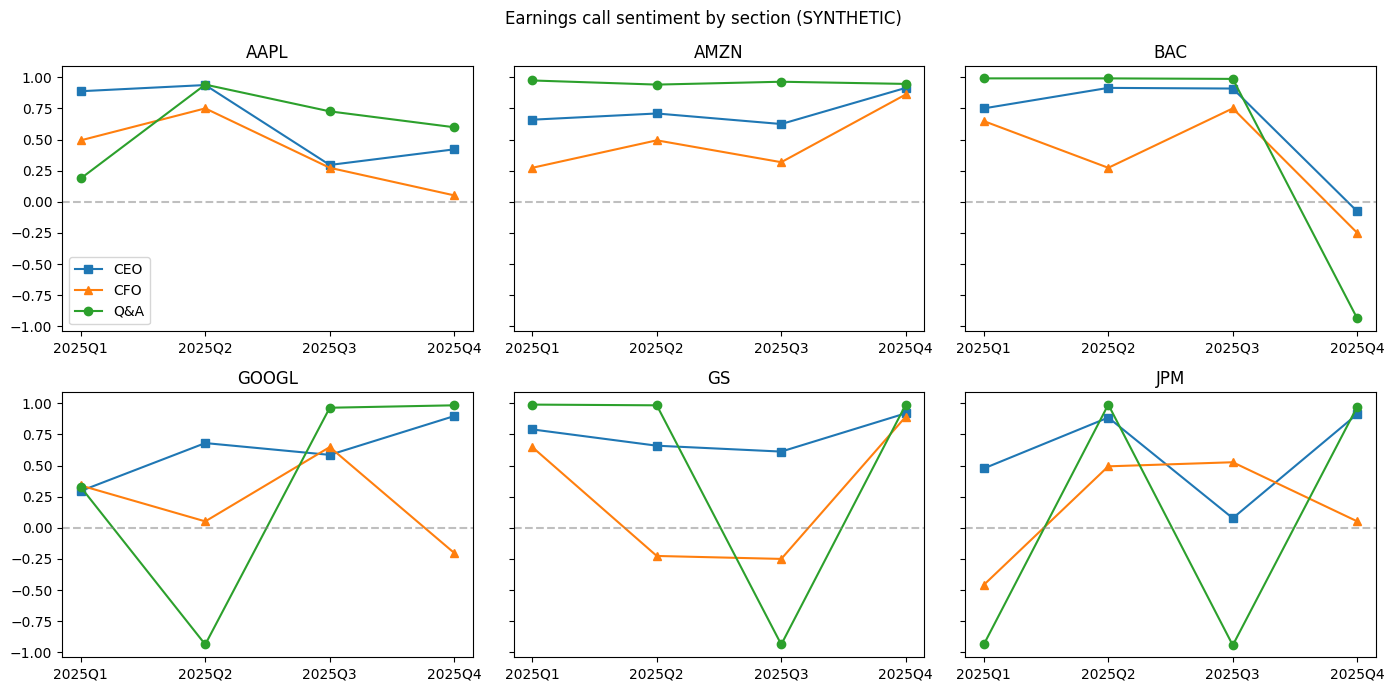

In [5]:
tickers_to_plot = sorted(merged["ticker"].unique())[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, tk in zip(axes.flat, tickers_to_plot):
    d = merged[merged["ticker"] == tk]
    for col, mk, lb in [("ceo_sentiment", "s", "CEO"), ("cfo_sentiment", "^", "CFO"), ("qa_sentiment", "o", "Q&A")]:
        ax.plot(d["period"], d[col], marker=mk, label=lb)
    ax.axhline(0, color="gray", ls="--", alpha=0.5)
    ax.set_title(tk)
axes.flat[0].legend()
fig.suptitle("Earnings call sentiment by section" + (" (SYNTHETIC)" if res["synthetic_transcripts"] else ""))
plt.tight_layout()
plt.savefig(RESULTS / "sentiment_trends.png", dpi=150)
plt.show()

In [6]:
merged.to_csv(RESULTS / "sentiment_vs_eps_surprise.csv", index=False)
pd.DataFrame([res]).to_csv(RESULTS / "sentiment_correlation_summary.csv", index=False)
print("Saved sentiment_vs_eps_surprise.csv and sentiment_correlation_summary.csv")

Saved sentiment_vs_eps_surprise.csv and sentiment_correlation_summary.csv
